# Random Forest

Many decision trees (notebook 03), each trained on a random sample of the rows and choosing each split from a random subset of features. The forest predicts by majority vote, which smooths out the mistakes of individual trees.

Two versions in `src/dosdetect/models.py`:

- `random_forest()`: 300 trees, default settings, plus an out-of-bag (OOB) accuracy estimate from the rows each tree skipped.
- `random_forest_tuned()`: tuned to catch DoS types it was never trained on (see the end of this notebook).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from dosdetect.data import prepare_all
from dosdetect.evaluate import evaluate, evaluate_all, metrics_table, plot_confusions
from dosdetect.models import MODELS

pd.set_option("display.precision", 4)

## Data

NSL-KDD, normal and DoS traffic only (`dosdetect.data.prepare_all`). Four setups:

- **official**: train on `KDDTrain+`, test on `KDDTest+`. About 23% of the test DoS rows are attack types never seen in training (apache2, mailbomb, processtable, udpstorm).
- **holdout**: stratified 80/20 split of `KDDTrain+`, so every test attack type was also seen in training.
- **8 features** (top 8 by |correlation| with the label, our reading of the paper's filter) or **all 41**. These are not exactly the paper's 8: it names `dst_bytes` and `protocol_type` among its features, and neither is in our top 8 (see the README).

In [2]:
data = prepare_all()
official = data[("official", 8)]
print("Train rows:", len(official["X_train"]), " Test rows:", len(official["X_test"]))
print("Unseen DoS rows in official test:", official["unseen"].sum())
official["prep"].correlations.head(8).rename("|correlation| with label").to_frame()

Train rows: 113270  Test rows: 17169
Unseen DoS rows in official test: 1717


,|correlation| with label
same_srv_rate,0.8654
dst_host_srv_serror_rate,0.7913
dst_host_serror_rate,0.7855
srv_serror_rate,0.7853
serror_rate,0.7850
dst_host_same_srv_rate,0.7600
flag,0.7567
dst_host_srv_count,0.7189


## Results

`recall_unseen` is the share of never-seen DoS attack types the model still catches (official split only).

In [3]:
results = evaluate_all(MODELS["random_forest"], data)
metrics_table(results)

,accuracy,precision,recall,f1,recall_seen,recall_unseen,train_time_s,predict_time_s
"official, 8 features",0.8461,0.9785,0.6602,0.7885,0.8140,0.1462,3.2757,0.1791
"official, 41 features",0.9027,0.9859,0.7873,0.8755,0.9962,0.0891,4.4696,0.1616
"holdout, 8 features",0.9604,0.9834,0.9179,0.9495,NaN,NaN,2.5646,0.1916
"holdout, 41 features",0.9999,0.9999,0.9998,0.9998,NaN,NaN,3.1145,0.1713


### Confusion matrices

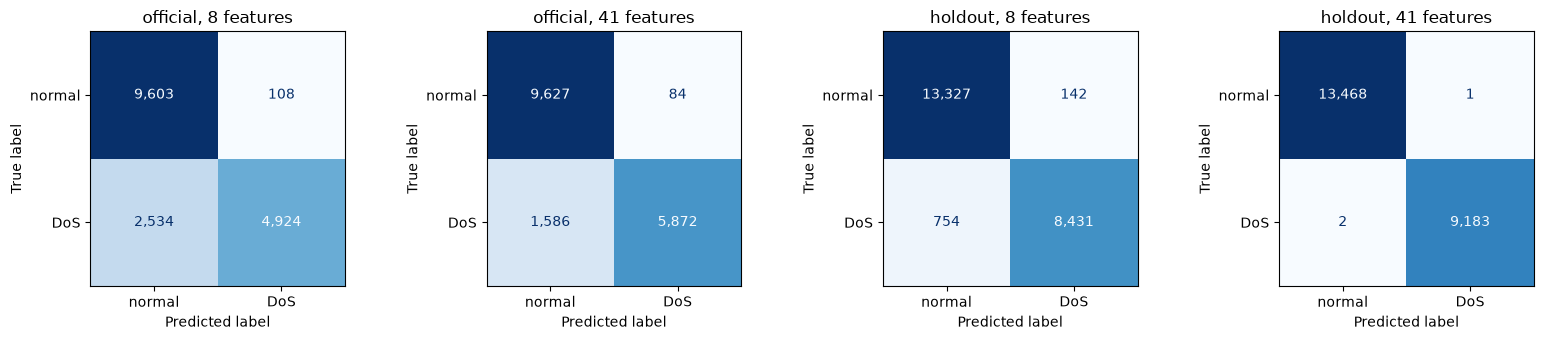

In [4]:
plot_confusions(results);

## Tuned Random Forest

`random_forest_tuned()` keeps the top 5 features by forest importance and uses shallower, regularised trees (`max_depth=10`, `min_samples_leaf=2`, `max_features=0.5`, `class_weight="balanced_subsample"`). The settings come from the attack-out search at the end of this notebook. It works best given all 41 features so it can choose its own.

In [5]:
tuned = evaluate_all(MODELS["random_forest_tuned"], data)
pd.concat({"default": metrics_table(results), "tuned": metrics_table(tuned)})[
    ["accuracy", "precision", "recall", "f1", "recall_unseen"]
]

accuracy  precision  recall      f1  \
default official, 8 features     0.8461     0.9785  0.6602  0.7885   
        official, 41 features    0.9027     0.9859  0.7873  0.8755   
        holdout, 8 features      0.9604     0.9834  0.9179  0.9495   
        holdout, 41 features     0.9999     0.9999  0.9998  0.9998   
tuned   official, 8 features     0.8636     0.9906  0.6925  0.8152   
        official, 41 features    0.9059     0.9893  0.7920  0.8797   
        holdout, 8 features      0.9598     0.9894  0.9107  0.9484   
        holdout, 41 features     0.9969     0.9928  0.9997  0.9962   

                               recall_unseen  
default official, 8 features          0.1462  
        official, 41 features         0.0891  
        holdout, 8 features              NaN  
        holdout, 41 features             NaN  
tuned   official, 8 features          0.2737  
        official, 41 features         0.2697  
        holdout, 8 features              NaN  
        holdout, 41 features             NaN

## Feature importance

Default forest, all 41 features, official split. Built-in importance (MDI, from training) next to permutation importance (F1 drop on the test set when one feature is shuffled). Showing the top 12 by either measure plus our top 8 by correlation. ~1.5 min.

,mdi,perm_f1_drop,abs_corr_with_label,in_top_8
src_bytes,0.1201,0.0714,0.0182,False
flag,0.1200,0.0129,0.7567,True
dst_host_srv_rerror_rate,0.0102,0.0122,0.1894,False
dst_host_rerror_rate,0.0067,0.0105,0.1952,False
dst_bytes,0.0725,0.0102,0.0404,False
protocol_type,0.0228,0.0081,0.2654,False
logged_in,0.0170,0.0071,0.6839,False
dst_host_same_srv_rate,0.0237,0.0055,0.7600,True


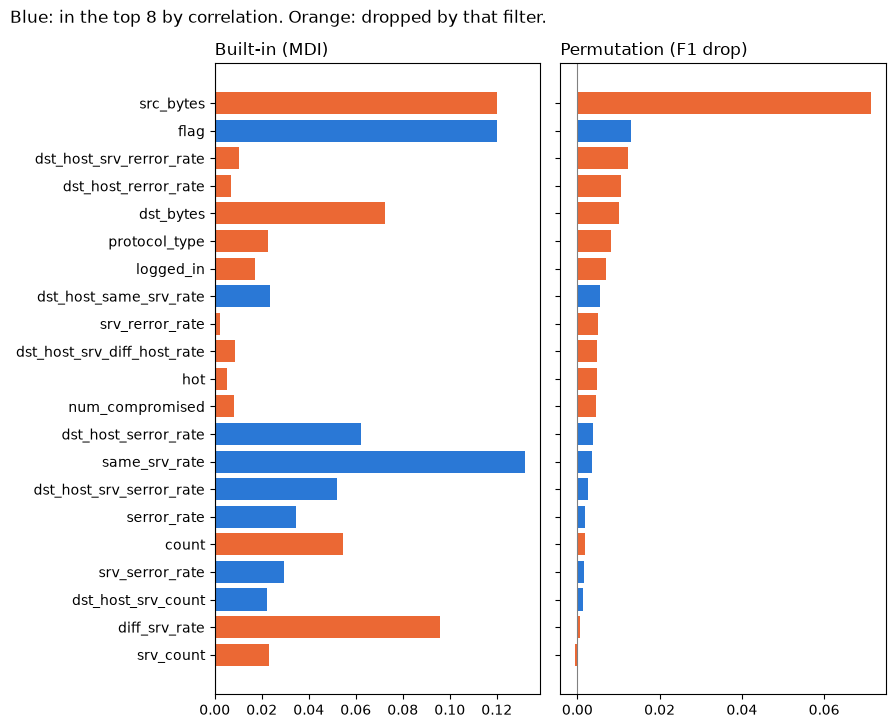

In [6]:
from sklearn.inspection import permutation_importance

full = data[("official", 41)]
forest = MODELS["random_forest"]().fit(full["X_train"], full["y_train"])
perm = permutation_importance(
    forest, full["X_test"], full["y_test"], scoring="f1", n_repeats=10, random_state=42
)

top_8 = data[("official", 8)]["prep"].selected_features
importance = pd.DataFrame(
    {
        "mdi": forest.feature_importances_,
        "perm_f1_drop": perm.importances_mean,
        "abs_corr_with_label": full["prep"].correlations.reindex(full["X_train"].columns).values,
        "in_top_8": full["X_train"].columns.isin(top_8),
    },
    index=full["X_train"].columns,
)
shown = importance[
    (importance["mdi"].rank(ascending=False) <= 12)
    | (importance["perm_f1_drop"].rank(ascending=False) <= 12)
    | importance["in_top_8"]
].sort_values("perm_f1_drop")

colors = ["#2a78d6" if kept else "#eb6834" for kept in shown["in_top_8"]]
fig, axes = plt.subplots(1, 2, figsize=(9, 0.28 * len(shown) + 1.5), sharey=True)
for ax, col, title in zip(
    axes, ["mdi", "perm_f1_drop"], ["Built-in (MDI)", "Permutation (F1 drop)"], strict=True
):
    ax.barh(shown.index, shown[col], color=colors)
    ax.axvline(0, color="grey", linewidth=0.8)
    ax.set_title(title, loc="left")
fig.suptitle(
    "Blue: in the top 8 by correlation. Orange: dropped by that filter.", x=0.01, ha="left"
)
fig.tight_layout()
importance.sort_values("perm_f1_drop", ascending=False).head(8)

### Does the correlation filter drop useful features?

`src_bytes` ties with `flag` for first on MDI and is clearly first on permutation, but it has almost no linear correlation with the label, so the top-8 correlation filter drops it. Retrain the default forest on a few feature sets to check. These sets were chosen *after* looking at test-set importance, so treat this as exploratory; the tuning below makes the same choice using training data only.

In [7]:
all_41 = list(full["X_train"].columns)
feature_sets = {
    "41 features": all_41,
    "41 minus src_bytes": [c for c in all_41 if c != "src_bytes"],
    "top 8": top_8,
    "top 8 + src_bytes": top_8 + ["src_bytes"],
    "top 8 + src_bytes, dst_bytes": top_8 + ["src_bytes", "dst_bytes"],
}
subset = lambda cols: {**full, "X_train": full["X_train"][cols], "X_test": full["X_test"][cols]}  # noqa: E731
metrics_table(
    {name: evaluate(MODELS["random_forest"](), subset(cols)) for name, cols in feature_sets.items()}
)[["f1", "recall_seen", "recall_unseen"]]

,f1,recall_seen,recall_unseen
41 features,0.8755,0.9962,0.0891
41 minus src_bytes,0.8637,0.9936,0.0076
top 8,0.7885,0.8140,0.1462
top 8 + src_bytes,0.8805,0.9645,0.2231
"top 8 + src_bytes, dst_bytes",0.8906,0.9744,0.2580


## How the tuned settings were chosen

Ordinary cross-validation can't tell candidates apart here: every attack type is in both training and validation, so every setting scores ~0.9998 F1. **Attack-out CV** instead hides one group of DoS types per fold (`neptune` | `smurf` | `back`+`land` | `teardrop`+`pod`) plus 1/4 of normal rows, imitating `KDDTest+`'s unseen attacks with training data only. The search also picks how many features to keep (top-k by forest importance, ranked inside each fold).

The search takes ~10 min, so by default this shows the saved results (`results/rf_tuning.csv`: each config trained with 5 seeds, scored on `KDDTest+`). Set `RUN_SEARCH = True` to rerun the attack-out search.

In [8]:
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectFromModel
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline

from dosdetect.data import RESULTS_DIR

RUN_SEARCH = False

SEARCH_SPACE = {
    "select__max_features": [5, 8, 10, 15, 20, 41],
    "rf__max_features": ["sqrt", "log2", 0.3, 0.5],
    "rf__min_samples_leaf": [1, 2, 5, 10, 20],
    "rf__max_depth": [None, 10, 20, 30],
    "rf__max_samples": [None, 0.5, 0.8],
    "rf__class_weight": [None, "balanced", "balanced_subsample"],
    "rf__criterion": ["gini", "entropy"],
}
HELD_OUT = [["neptune"], ["smurf"], ["back", "land"], ["teardrop", "pod"]]


def attack_out_folds(train_df, seed=42):
    """Each fold validates on one held-out DoS group plus 1/4 of normal rows."""
    normal = np.flatnonzero(train_df["label"].to_numpy() == 0)
    chunks = np.array_split(np.random.default_rng(seed).permutation(normal), len(HELD_OUT))
    for attacks, chunk in zip(HELD_OUT, chunks, strict=True):
        val = np.concatenate([np.flatnonzero(train_df["attack"].isin(attacks)), chunk])
        yield np.setdiff1d(np.arange(len(train_df)), val), val


if RUN_SEARCH:
    pipe = Pipeline(
        [
            (
                "select",
                SelectFromModel(
                    RandomForestClassifier(n_estimators=50, n_jobs=-1, random_state=42),
                    threshold=-np.inf,
                ),
            ),
            ("rf", RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)),
        ]
    )
    search = RandomizedSearchCV(
        pipe,
        SEARCH_SPACE,
        n_iter=30,
        scoring="f1",
        cv=list(attack_out_folds(full["train_df"])),
        random_state=42,
        refit=False,
    ).fit(full["X_train"], full["y_train"])
    print(f"best attack-out CV F1 {search.best_score_:.4f}:", search.best_params_)

pd.read_csv(RESULTS_DIR / "rf_tuning.csv", index_col="config").drop(columns="params")

,f1_mean,recall_seen_mean,recall_unseen_mean,f1_std,recall_seen_std,recall_unseen_std
config,,,,,,
"default, top 8",0.7859,0.8128,0.1289,0.0023,0.0008,0.0124
"default, 41",0.8726,0.9954,0.0727,0.0040,0.0008,0.0263
tuned (standard CV),0.8886,0.9956,0.1877,0.0040,0.0008,0.0288
tuned (attack-out CV),0.8893,0.9613,0.2973,0.0132,0.0182,0.1075


## Takeaways

- **On the official file, averaging 300 trees barely beats one tree.** The default forest scores 90.3% accuracy with 41 features versus 90.5% for the single decision tree. On the holdout split it is near-perfect (99.99%), but so is the tree.
- **The default forest is worst at new attack types**: 9–15% recall on never-seen DoS types. It fits known attacks very tightly.
- **Feature importance disagrees with the correlation filter.** The forest relies most on `src_bytes` and `flag`. `src_bytes` has almost no linear correlation with the label (0.02), so the top-8 filter drops it; adding it back to the top 8 raises F1 from 0.79 to 0.88. Removing it from the 41 barely changes F1 but drops unseen-type recall to ~0.
- **Even within the training data, a forest can't catch DoS types it hasn't seen**: the best attack-out CV F1 is only 0.16. This reproduces the official split's weakness without touching test data.
- **Attack-out tuning helps where it was aimed.** Over 5 seeds the tuned forest reaches 0.889 F1 (default 41: 0.873) and roughly 4x the unseen-type recall (0.30 vs 0.07), using only 5 features. The cost: seen recall drops from 0.995 to 0.961 and results vary more by seed.